**Before starting this practical session**:

1. **Change the runtime type on Google Colab**: `Runtime > Change runtime type > T4 GPU`
2. **Install the packages below**:

In [1]:
! pip install lightning torchmetrics torchinfo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 28.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 39.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 32.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [lightning]


3. Run this code to suppress some messages and warnings that may be displayed.

In [2]:
import logging
logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch.utilities.rank_zero").setLevel(logging.WARNING)
logging.getLogger("lightning.pytorch.accelerators.cuda").setLevel(logging.WARNING)
logger = logging.getLogger("lightning")
logger.propagate = False

import warnings
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*Missing logger folder.*")
warnings.filterwarnings("ignore", "`isinstance\\(treespec, LeafSpec\\)` is deprecated.*")

# Image classification with a convolutional neural network

## Loading the data

We will work on a dataset called [EMNIST](https://www.westernsydney.edu.au/icns/resources/reproducible_research3/publication_support_materials2/emnist), and more specifically on a subset consisting of grayscale images of handwritten letters.
To do this, we will use the [`torchvision.datasets.EMNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.EMNIST.html) class to download and load this dataset.

In [3]:
import torch
from torchvision.datasets import EMNIST
from torchvision.transforms import v2


dataset_train = EMNIST(
    root="data",
    split="letters",
    download=True,
    train=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
    target_transform=lambda x: x - 1
)

dataset_val = EMNIST(
    root="data",
    split="letters",
    download=True,
    train=False,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
    target_transform=lambda x: x - 1
)

100%|██████████| 562M/562M [00:02<00:00, 263MB/s]


### Question 1

**a)** Compute the size of the training and validation sets, i.e., the number of images in each of the two sets.

**b)** Compute the size of an observation, i.e., the size of an image. We will assume that all observations have the same size (this is indeed the case, you do not need to verify it).

In [7]:
n_train = dataset_train.data.shape[0]
n_val = dataset_val.data.shape[0]

print(f"There are {n_train} training observations.")
print(f"There are {n_val} validation observations")

img_size = dataset_train.data.shape[1] * dataset_train.data.shape[2]

print(f"The observation size is {img_size}")

There are 124800 training observations.
There are 20800 validation observations
The observation size is 784


There are 26 classes in this dataset, corresponding to the 26 letters of the alphabet. However, the dataset mixes uppercase and lowercase letters: images for the letters *A* and *a* therefore have the same label.

The code below displays nine observations randomly drawn from the training set.

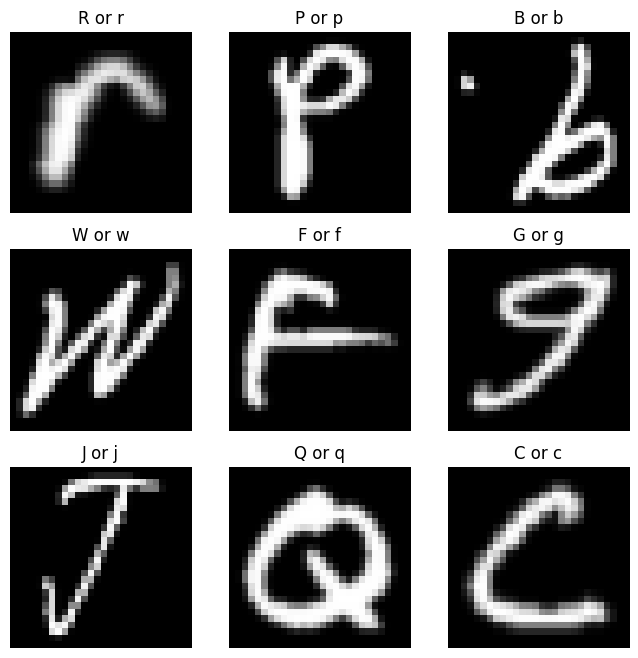

In [8]:
import matplotlib.pyplot as plt


figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(dataset_train), size=(1,)).item()
    img, label = dataset_train[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(f"{chr(65 + label)} or {chr(97 + label)}")
    plt.axis("off")
    plt.imshow(img.squeeze().T, cmap="gray")
plt.show()

### Question 2

You may have noticed the following code in the creation of the datasets:

```python
transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
target_transform=lambda x: x - 1
```

By reading the documentation of the [`torchvision.datasets.EMNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.EMNIST.html) class, you will see that:
* the `transform` argument transforms the raw image,
* the `target_transform` argument transforms the label.

**a)** Explain the purpose of the code transforming the inputs. To do this, for the first observation of the training set, display the tensor of the raw input and the tensor of the transformed input. In particular, compare the size, the data type (*dtype*), and the minimum and maximum values for these two tensors.

> **Note**: you can access the raw data of this dataset through the `data` attribute (e.g., `dataset_train.data`)

**b)** Explain the purpose of the code transforming the labels.

> **Note**: you can access the raw label mapping of this dataset through the `class_to_idx` attribute (e.g., `dataset_train.class_to_idx`). You may assume, without verifying it, that there is no missing label (`'N/A'`) in either of the two datasets.

In [49]:
print(dataset_train.data[0])
print(dataset_train[0])

print(dataset_train.data[0].shape)
print(dataset_train[0][0].shape) #The second indexing is needed because with only one index i retrieve a tuple containing the observation and its label, bur i only want the observation.

print(dataset_train.data[0].min())
print(dataset_train.transform(dataset_train.data)[0].min())

print(dataset_train.data[0].max())
print(dataset_train.transform(dataset_train.data)[0].max())

tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,  20, 114, 125,  82,  37,  37,  39, 115, 157,  94,  21,  10,
          32,  37,  37,  37,  37,  37,  37,  37,  82, 125, 114,  20,   0,   0],
        [  0,   3, 109, 245, 249, 233, 217, 217, 217, 245, 251, 234, 172, 142,
         203, 217, 217, 217, 217, 217, 217, 217, 233, 249, 245, 109,   3,   0],
        [  0,   4, 114, 253, 254, 254, 254, 254, 254, 254, 254, 254, 252, 251,
         254, 254, 254, 254, 254, 254, 254, 254, 254, 254, 254, 127,   4,   0],
        [  0,   0,  45, 214, 233, 251, 254, 25

**Answers**:
    
**a)** We are transforming each observation as an Image (i.e. adding an additional dimension for channels if not already present through the ToImage function), then rescaling it, converting its values into float32 types and rescaling them to the range that is expected for images. The size of the images remains the same. The scaling goes from [0,255] to [0,1]

**b)** We are shifting class labels so that they map from 0 to K, rather than from 1 to K+1, because the former is what is expected when using pythorch.

### Question 3

Compute the class distribution on the training and validation sets. Are the classes balanced? Is accuracy an appropriate metric for evaluating a model's performance?

> **Remark**: You can use one of the following functions to compute the distribution of an array or a tensor of non-negative integers: [`numpy.unique()`](https://numpy.org/doc/stable/reference/generated/numpy.unique.html), [`numpy.bincount()`](https://numpy.org/doc/stable/reference/generated/numpy.bincount.html) or [`torch.bincount()`](https://pytorch.org/docs/stable/generated/torch.bincount.html).

In [38]:
import numpy as np

np.unique(dataset_train.train_labels, return_counts=True) #The classes are perfectly balanced, hence accuracy would be an appropriate metric.

/usr/local/lib/python3.13/dist-packages/torchvision/datasets/mnist.py:66: UserWarning: train_labels has been renamed targets
  warnings.warn("train_labels has been renamed targets")


(array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26]),
 array([4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800,
        4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800,
        4800, 4800, 4800, 4800]))

### Question 4

Build the *dataloaders* for the training and validation sets. Use batches of size *64*. Shuffle the observations on the training set.

In [40]:
from torch.utils.data import DataLoader

dataloader_train = DataLoader(dataset_train, batch_size=64, shuffle=True)
dataloader_val = DataLoader(dataset_val, batch_size=64, shuffle=False)

## A first convolutional neural network

### Question 5

The following code is a draft definition of a convolutional neural network. Answer the following questions:

**a)** Which layers are convolutional layers?

**b)** Why is the number of input channels set to `1` in `self.cv1`?

**c)** Indicate, for `self.cv1`, the number of output channels, the kernel size, and the stride.

**d)** What type of pooling layer does this network consist of?

**e)** Which layers have trainable parameters?

In [58]:
import lightning as L
from torchmetrics import Accuracy


class CNN(L.LightningModule):  # Always inherit from the lightning.LightningModule class
    def __init__(self):
        """Constructor.

        In the constructor, we always run the constructor of the parent class and we
        instantiate all the elements of our network: the layers, the activation functions,
        the loss function and the metrics.
        """
        super().__init__()  # Always run the constructor of the parent class

        # Instantiate the layers and activation functions
        self.cv1 = torch.nn.Conv2d(in_channels=1, out_channels=4, kernel_size=5, padding="same")
        self.relu1 = torch.nn.ReLU()
        self.pool1 = torch.nn.MaxPool2d(kernel_size=2, stride=2)
        self.flatten = torch.nn.Flatten()
        self.fc2 = torch.nn.Linear(784, 64)
        self.relu2 = torch.nn.ReLU()
        self.fc3 = torch.nn.Linear(64, 26)

        # Instantiate the loss function
        self.loss = torch.nn.CrossEntropyLoss()

        # Instantiate the metrics
        self.accuracy_train = Accuracy(task="multiclass", num_classes=26)
        self.accuracy_val = Accuracy(task="multiclass", num_classes=26)

    def forward(self, x):
        """Implements the forward pass."""
        out = self.cv1(x)
        out = self.relu1(out)
        out = self.pool1(out)
        out = self.flatten(out)
        out = self.fc2(out)
        out = self.relu2(out)
        out = self.fc3(out)
        return out

    def step(self, batch, dataset):
        """Perform a step.

        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : tuple
            A batch of samples.

        dataset : {"training", "validation"}
            Data set used.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """

        x, y = batch  # x corresponds to the images, y to the classes (labels)
        logits = self(x)  # Forward pass outputting the logits
        loss = self.loss(logits, y)  # Evaluation of the loss function
        y_pred = logits.argmax(1)  # Predictions of the model

        if dataset == "training":
            metric = self.accuracy_train
            name = "train"
            bar_step = True
        else:
            metric = self.accuracy_val
            name = "val"
            bar_step = False

        acc = metric(y_pred, y)
        self.log(f"loss_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"accuracy_{name}", acc, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Perform a training step."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Perform a validation step."""
        return self.step(batch, "validation")

    def on_train_start(self):
        """Code to run at the beginning of training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -----------------------------------------
            |  Data set  | Loss function | Accuracy |
            | ---------- | ------------- | -------- |
            |  Training  |{metrics['loss_train'].item():^15.5f}|{metrics['accuracy_train'].item():^10.4%}|
            | Validation |{metrics['loss_val'].item():^15.5f}|{metrics['accuracy_val'].item():^10.4%}|
            -----------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.strip().split("\n")])
        print(string, "\n")

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        optimizer = torch.optim.Adam(self.parameters())
        return optimizer

**Answers**:

**a)** The self.cv1 layer is a convolutional layer.

**b)** The number of channels is set to 1 because the images are grayscale, so there is only one input channel.

**c)** The number of output channels is 4, the kernel size is 5x5, and the stride has its default value, i.e. 1.

**d)** It has a maximum pooling layer.

**e)** The convolutional layer and the two linear layers.

### Question 6

When trying to display the architecture summary of our model with the code below, an error will be raised. Identify the problem corresponding to this error and fix it. Explain, in words, what the problem was.

In [59]:
from torchinfo import summary


summary(CNN(), input_size=(64, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [64, 26]                  --
├─Conv2d: 1-1                            [64, 4, 28, 28]           104
├─ReLU: 1-2                              [64, 4, 28, 28]           --
├─MaxPool2d: 1-3                         [64, 4, 14, 14]           --
├─Flatten: 1-4                           [64, 784]                 --
├─Linear: 1-5                            [64, 64]                  50,240
├─ReLU: 1-6                              [64, 64]                  --
├─Linear: 1-7                            [64, 26]                  1,690
Total params: 52,034
Trainable params: 52,034
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 8.54
Input size (MB): 0.20
Forward/backward pass size (MB): 1.65
Params size (MB): 0.21
Estimated Total Size (MB): 2.06

**Answer**: The number of inputs for the linear layer was wrong.

### Question 7

Train your model for 10 epochs. Compare the model's performance to that expected for a trivial model (which would always predict the same class or would predict classes completely randomly).

In [60]:
from lightning.pytorch.callbacks import TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger


model = CNN()

trainer = L.Trainer(
    max_epochs=10,
    enable_model_summary=False,  # disable model summary
    logger=CSVLogger('.'),  # save the results in a CSV file
    num_sanity_val_steps=0,  # do not perform any validation step before training
    callbacks=[TQDMProgressBar(refresh_rate=100)]  # update the progress bar every 100 batches
)

trainer.fit(
    model=model,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)

Training: |          | 0/? [00:00<?, ?it/s]

Version 0



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 1 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.83410    | 75.1755% |
| Validation |    0.51322    | 84.3606% |
----------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 2 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.43559    | 86.4479% |
| Validation |    0.38166    | 88.4231% |
----------------------------------------- 



... (12 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 9 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.21407    | 92.6731% |
| Validation |    0.27890    | 91.3702% |
----------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 10 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.20665    | 92.9760% |
| Validation |    0.28036    | 91.3798% |
----------------------------------------- 



**Answer**: The model performs much better than random guessing, since in that case we would expect only about 4% accuracy, given we have 26 classes.

### Question 8

Visualize the model's performance curves using the `plot_loss_accuracy` function defined below. You can use the `version` argument to indicate which version of the model to choose.

In [61]:
def plot_loss_accuracy(savedir=".", version=None):
    """Plot the loss function and accuracy curves.

    Parameters
    ----------
    savedir : str (default = ".")
        Path to the results.

    version : int or None (default = None)
        Version number of the model.
    """
    # Get the results as a pandas.DataFrame
    import os
    import pandas as pd
    if version is None:
        version = max([
            int(folder.split("version_")[1])
            for folder in os.listdir(os.path.join(savedir, "lightning_logs"))
            if folder.startswith("version")
        ])
    df = pd.read_csv(os.path.join(savedir, "lightning_logs", f"version_{version}", "metrics.csv"))
    df["epoch"] += 1  # Start counting the epochs from 1 instead of 0

    loss_train = df.dropna(subset="loss_train_epoch").set_index("epoch")["loss_train_epoch"]
    loss_val = df.dropna(subset="loss_val").set_index("epoch")["loss_val"]

    accuracy_train = df.dropna(subset="accuracy_train_epoch").set_index("epoch")["accuracy_train_epoch"]
    accuracy_val = df.dropna(subset="accuracy_val").set_index("epoch")["accuracy_val"]

    # Plot the results
    plt.figure(figsize=(13, 4))

    plt.subplot(1, 2, 1)
    plt.plot(loss_train.index, loss_train.to_numpy(), "o-", label="Training");
    plt.plot(loss_val.index, loss_val.to_numpy(), "o-", label="Validation");
    plt.xlabel("Epoch")
    plt.ylabel("Loss function")
    plt.legend();

    plt.subplot(1, 2, 2)
    plt.plot(accuracy_train.index, accuracy_train.to_numpy(), "o-", label="Training");
    plt.plot(accuracy_val.index, accuracy_val.to_numpy(), "o-", label="Validation");
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend();

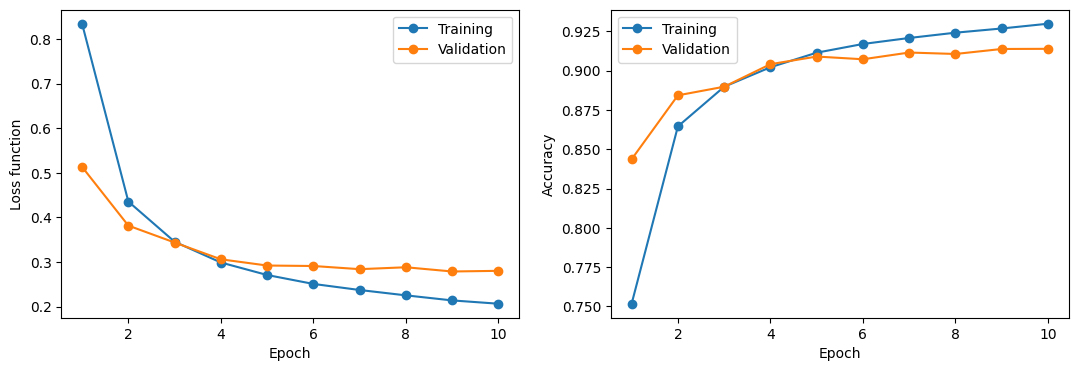

In [62]:
plot_loss_accuracy()

## A second convolutional neural network

### Question 9

Complete the `__init__()` method of the `LeNet5` class defined below, whose sequential architecture is described below, corresponding to the [LeNet5](https://en.wikipedia.org/wiki/LeNet) architecture:

* a convolutional layer with $6$ output channels, a kernel of size $5 \times 5$, and padding such that the output image has the same size as the input image.
* the sigmoid activation function.
* a max pooling layer with a kernel of size $2 \times 2$ and a stride of $2$.
* a convolutional layer with $16$ output channels, a kernel of size $5 \times 5$, and no padding.
* the sigmoid activation function.
* a max pooling layer with a kernel of size $2 \times 2$ and a stride of $2$.
* a flatten layer.
* a linear layer with an input of size $400$ and an output of size $256$.
* the sigmoid activation function.
* a linear layer with an output of size $128$.
* the sigmoid activation function.
* a linear layer with an output of size $26$.

Here are the links to the documentation of the corresponding classes:
[`torch.nn.Conv2d()`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html),
[`torch.nn.Sigmoid()`](https://pytorch.org/docs/stable/generated/torch.nn.Sigmoid.html),
[`torch.nn.MaxPool2d()`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html),
[`torch.nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html), and
[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html).

In [71]:
class LeNet5(L.LightningModule):  # Always inherit from the lightning.LightningModule class
    def __init__(self):
        """Constructor.

        In the constructor, we always run the constructor of the parent class and we
        instantiate all the elements of our network: the layers, the activation functions,
        the loss function and the metrics.
        """
        super().__init__()  # Always run the constructor of the parent class

        ### BEGIN TODO ###
        self.sequential = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, padding="same"),
            torch.nn.Sigmoid(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),
            torch.nn.Flatten(),
            torch.nn.Linear(in_features=1176, out_features=256),
            torch.nn.Sigmoid(),
            torch.nn.Linear(256, 128),
            torch.nn.Sigmoid(),
            torch.nn.Linear(128, 26),
        )
        #### END TODO ####

        # Instantiate the loss function
        self.loss = torch.nn.CrossEntropyLoss()

        # Instantiate the metrics
        self.accuracy_train = Accuracy(task="multiclass", num_classes=26)
        self.accuracy_val = Accuracy(task="multiclass", num_classes=26)

    def forward(self, x):
        """Implements the forward pass."""
        ### BEGIN TODO ###
        y = self.sequential(x)
        #### END TODO ####
        return y

    def step(self, batch, dataset):
        """Perform a step.

        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : tuple
            A batch of samples.

        dataset : {"training", "validation"}
            Data set used.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """

        x, y = batch  # x corresponds to the images, y to the classes (labels)
        logits = self(x)  # Forward pass outputting the logits
        loss = self.loss(logits, y)  # Evaluation of the loss function
        y_pred = logits.argmax(1)  # Predictions of the model

        if dataset == "training":
            metric = self.accuracy_train
            name = "train"
            bar_step = True
        else:
            metric = self.accuracy_val
            name = "val"
            bar_step = False

        acc = metric(y_pred, y)
        self.log(f"loss_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"accuracy_{name}", acc, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Perform a training step."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Perform a validation step."""
        return self.step(batch, "validation")

    def on_train_start(self):
        """Code to run at the beginning of the training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -----------------------------------------
            |  Data set  | Loss function | Accuracy |
            | ---------- | ------------- | -------- |
            |  Training  |{metrics['loss_train'].item():^15.5f}|{metrics['accuracy_train'].item():^10.4%}|
            | Validation |{metrics['loss_val'].item():^15.5f}|{metrics['accuracy_val'].item():^10.4%}|
            -----------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.strip().split("\n")])
        print(string, "\n")

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        optimizer = torch.optim.Adam(self.parameters())
        return optimizer

### Question 10

Display a summary of this architecture. How many trainable parameters does this architecture have?

In [72]:
summary(LeNet5(), input_size=(64, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
LeNet5                                   [64, 26]                  --
├─Sequential: 1-1                        [64, 26]                  --
│    └─Conv2d: 2-1                       [64, 6, 28, 28]           156
│    └─Sigmoid: 2-2                      [64, 6, 28, 28]           --
│    └─MaxPool2d: 2-3                    [64, 6, 14, 14]           --
│    └─Flatten: 2-4                      [64, 1176]                --
│    └─Linear: 2-5                       [64, 256]                 301,312
│    └─Sigmoid: 2-6                      [64, 256]                 --
│    └─Linear: 2-7                       [64, 128]                 32,896
│    └─Sigmoid: 2-8                      [64, 128]                 --
│    └─Linear: 2-9                       [64, 26]                  3,354
Total params: 337,718
Trainable params: 337,718
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 29.43
Input size (MB): 0.20
Forward

**Answer**: The number of trainable parameters is 337,718

### Question 11

Train your new neural network for 10 epochs. Compare its performance to that of the previous model.

In [73]:
model_lenet = LeNet5()

trainer_lenet = L.Trainer(
    max_epochs=10,
    enable_model_summary=False,  # disable model summary
    logger=CSVLogger('.'),  # save the results in a CSV file
    num_sanity_val_steps=0,  # do not perform any validation step before training
    callbacks=[TQDMProgressBar(refresh_rate=100)]  # update the progress bar every 100 batches
)

trainer_lenet.fit(
    model=model_lenet,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)

Training: |          | 0/? [00:00<?, ?it/s]

Version 1



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 1 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    1.34523    | 61.2957% |
| Validation |    0.67283    | 80.1731% |
----------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 2 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.52890    | 83.8630% |
| Validation |    0.44791    | 86.0144% |
----------------------------------------- 



... (12 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 9 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.19293    | 93.3702% |
| Validation |    0.26556    | 91.6538% |
----------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 10 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.18150    | 93.7276% |
| Validation |    0.24108    | 92.2404% |
----------------------------------------- 



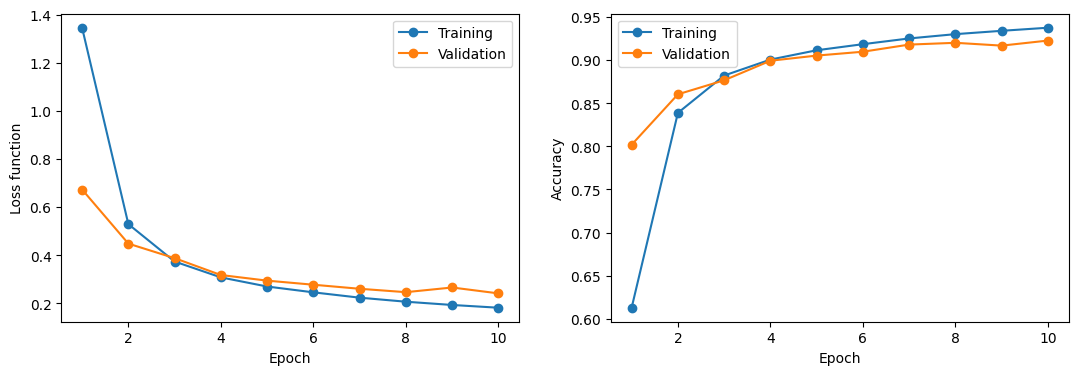

In [74]:
plot_loss_accuracy()

**Answer**: The performance is better compared to the previous model.